# Causal decoder and next-token prediction

A three-symbol motif repeats three times. Its first occurrences are hard to guess, but every later token has an exact match in the prefix.

A decoder-only transformer uses a causal self-attention mask. Loss is computed on every next-token prediction. At evaluation, the first two targets and the repeated targets are reported separately.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


from itertools import product


def split_sequences(vocab, width, n_train):
    seq = torch.tensor(list(product(range(vocab), repeat=width)), dtype=torch.long)
    order = torch.randperm(len(seq), generator=torch.Generator().manual_seed(73))
    return seq[order[:n_train]], seq[order[n_train:]]


def encoder(width=32):
    return nn.TransformerEncoderLayer(
        d_model=width, nhead=4, dim_feedforward=64, dropout=0, batch_first=True, activation="gelu"
    )


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(8, 32)
        self.position = nn.Parameter(torch.randn(8, 32) * 0.12)
        self.block = encoder()
        self.out = nn.Linear(32, 8)

    def forward(self, tokens):
        n = tokens.shape[1]
        mask = torch.ones(n, n, dtype=torch.bool, device=tokens.device).triu(1)
        h = self.embedding(tokens) + self.position[:n]
        return self.out(self.block(h, src_mask=mask))

## Fit on disjoint motifs

The network sees eight prefix positions at a time. A strict upper-triangular mask prevents a position from seeing its own next-token target.

In [2]:
seed()
train, test = split_sequences(8, 3, 400)
train, test = train.repeat(1, 3), test.repeat(1, 3)
model = Decoder()
opt = torch.optim.AdamW(model.parameters(), lr=0.004)
losses = []
for epoch in range(26):
    total = 0.0
    for ids in torch.randperm(len(train)).split(50):
        seq = train[ids]
        logits = model(seq[:, :-1])
        loss = F.cross_entropy(logits.flatten(0, 1), seq[:, 1:].flatten())
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(ids)
    losses.append(total / len(train))

## Check the prefix and score greedy continuation

The held-out scores condition on the true prefix. Greedy continuation instead feeds the model its own predictions, starting from three observed symbols.

,Target group,Tokens,Accuracy,NLL (nats),Perplexity
0,First occurrences,224,0.06696,2.1730,8.78459
1,Repeats,672,1.00000,0.0054,1.00542


Exact six-token greedy continuation: 1.000 on 112 held-out motifs


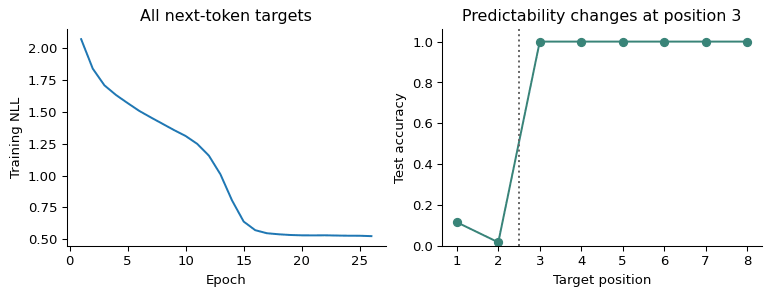

In [3]:
model.eval()
with torch.no_grad():
    inputs, targets = test[:, :-1], test[:, 1:]
    logits = model(inputs)
    changed = inputs.clone()
    changed[:, 4:] = (changed[:, 4:] + 1) % 8
    assert torch.allclose(logits[:, :4], model(changed)[:, :4], atol=2e-6)
    nll = F.cross_entropy(logits.flatten(0, 1), targets.flatten(), reduction="none").view_as(
        targets
    )
    hits = logits.argmax(-1) == targets
    rows = []
    for name, seg in [("First occurrences", slice(0, 2)), ("Repeats", slice(2, None))]:
        loss = nll[:, seg].mean().item()
        rows.append(
            (
                name,
                targets[:, seg].numel(),
                hits[:, seg].float().mean().item(),
                loss,
                np.exp(loss),
            )
        )
    tokens = test[:, :3].clone()
    for _ in range(6):
        tokens = torch.cat((tokens, model(tokens)[:, -1].argmax(-1, keepdim=True)), dim=1)
    exact = (tokens == test).all(1).float().mean().item()
report(["Target group", "Tokens", "Accuracy", "NLL (nats)", "Perplexity"], rows)
print(f"Exact six-token greedy continuation: {exact:.3f} on {len(test)} held-out motifs")
fig, axes = plt.subplots(1, 2, figsize=(8, 3), layout="constrained")
axes[0].plot(range(1, len(losses) + 1), losses)
axes[0].set(xlabel="Epoch", ylabel="Training NLL", title="All next-token targets")
axes[1].plot(range(1, 9), hits.float().mean(0), "o-", color="#398478")
axes[1].axvline(2.5, ls=":", color="0.4")
axes[1].set(
    xlabel="Target position",
    ylabel="Test accuracy",
    ylim=(0, 1.06),
    title="Predictability changes at position 3",
)
plt.show()

## Interpreting the result

All 112 unseen motifs continued correctly for six greedy steps after their three-symbol prefix. Next-token accuracy on the first two targets was only 6.7%. Averaging across those two types of target would conceal their different information content.

The position-wise curve distinguishes retrieval of a repeated motif from guessing the initial symbols. Exact continuation demands six consecutive correct decisions.

## Exercise

Change the motif length to four and extend the learned position table. Does the model still discover the correct lag?

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)

[Radford et al. (2018), Improving Language Understanding by Generative Pre-Training](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)